## EDA de los datasets ##

El presente notebook tiene como intención el realizar una analisis exploratorio de los datos que serán utilizados para los modelos del proyecto. Buscamos definir: variables de entrada y su naturaleza, variable objetivo, decisiones a tomar para la transformación de los datos.

# Importación de bibliotecas y datos

In [1]:
# Importación de bibliotecas
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import seaborn as sns
import os
import kagglehub
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score, confusion_matrix, silhouette_score, davies_bouldin_score, calinski_harabasz_score
import mlflow
import mlflow.sklearn
import argparse

d:\00 Clases\TEC Monterrey\Cursos\4to Trimestre\Operaciones de aprendizaje automático\Tareas\mlops_tec\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Importación de datos

# Definir la ruta a la carpeta de datos procesados
processed_dir = Path("../data/processed")

# Buscar todos los archivos Parquet de viajes usando glob
parquet_files = sorted(processed_dir.glob("trips_*.parquet"))

# Lista temporal para guardar los DataFrames de cada mes
df_list = []

# Ciclo for para leer cada archivo y agregarlo a la lista
for file_path in parquet_files:
  print(f"Cargando: {file_path.name}")
  temp_df = pd.read_parquet(file_path)
  df_list.append(temp_df)

# Unir todos los DataFrames en uno solo grande
df_trips_all = pd.concat(df_list, ignore_index=True)

# Cargar el catálogo de estaciones
df_stations = pd.read_parquet(processed_dir / "stations.parquet")

print("\n¡Carga completa!")
print(f"Total de registros combinados: {df_trips_all.shape}")
df_trips_all.head()
print(f"Total de estaciones: {df_stations.shape}")

Cargando: trips_2024_09.parquet
Cargando: trips_2024_10.parquet
Cargando: trips_2024_11.parquet
Cargando: trips_2024_12.parquet
Cargando: trips_2025_01.parquet
Cargando: trips_2025_02.parquet
Cargando: trips_2025_03.parquet
Cargando: trips_2025_04.parquet
Cargando: trips_2025_05.parquet
Cargando: trips_2025_06.parquet
Cargando: trips_2025_07.parquet
Cargando: trips_2025_08.parquet
Cargando: trips_2025_09.parquet
Cargando: trips_2025_10.parquet
Cargando: trips_2025_11.parquet
Cargando: trips_2025_12.parquet
Cargando: trips_2026_01.parquet
Cargando: trips_2026_02.parquet
Cargando: trips_2026_03.parquet
Cargando: trips_2026_04.parquet
Cargando: trips_2026_05.parquet
Cargando: trips_2026_06.parquet
Cargando: trips_2026_07.parquet
Cargando: trips_2026_08.parquet
Cargando: trips_2026_09.parquet

¡Carga completa!
Total de registros combinados: (9433997, 5)
Total de estaciones: (484, 5)


# Exploración de los datos

Iniciamos con la visualización de algunos datos, ver los campos y el tipo de dato

In [3]:
#Hacemos una info() de nuestras variables para ver el tipo de dato y si hay nulos
print('Información de viajes:')
df_trips_all.info()

print('Información de estaciones:')
df_stations.info() 

Información de viajes:
<class 'pandas.DataFrame'>
RangeIndex: 9433997 entries, 0 to 9433996
Data columns (total 5 columns):
 #   Column                  Dtype         
---  ------                  -----         
 0   trip_id                 string        
 1   start_time              datetime64[us]
 2   end_time                datetime64[us]
 3   origin_station_id       string        
 4   destination_station_id  string        
dtypes: datetime64[us](2), string(3)
memory usage: 477.5 MB
Información de estaciones:
<class 'pandas.DataFrame'>
RangeIndex: 484 entries, 0 to 483
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   station_id    484 non-null    string 
 1   station_name  484 non-null    string 
 2   latitude      484 non-null    float64
 3   longitude     484 non-null    float64
 4   capacity      484 non-null    int64  
dtypes: float64(2), int64(1), string(2)
memory usage: 40.2 KB


df_trips_all

- Vemos que hay unos datos identificados como origin_station_id y destination_station_id que están como string en el dataframe  y por su nombre son identificadores, por lo tanto deben de ser datos integer. Podría requerirse una transformación de ese tipo de dato. 

df_stations
- También se observa una variable de nombre station_id que se ve que es tipo string pero es un identificador, debe de ser cambiado a tipo integer. 

In [4]:
# Hacemos un head para ver como se estructura cada data set

print('Primeros registros de viajes:')
display(df_trips_all.head())

print('Primeros registros de estaciones:')
display(df_stations.head())

Primeros registros de viajes:


,trip_id,start_time,end_time,origin_station_id,destination_station_id
0,35406564,2024-01-09 00:00:00,2024-01-09 00:07:00,154,161
1,35406567,2024-01-09 00:02:00,2024-01-09 00:08:00,50,156
2,35406571,2024-01-09 00:02:00,2024-01-09 00:18:00,64,273
3,35406572,2024-01-09 00:03:00,2024-01-09 00:10:00,271,164
4,35406573,2024-01-09 00:03:00,2024-01-09 00:19:00,199,63


Primeros registros de estaciones:


,station_id,station_name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


df_trips_all
- Podemos obtener información del tiempo de duración del viaje usando el start_time y el end_time
- Podemos obtener información de comportamiento de los viajes como:¿De que estacion salen los viajes? ¿Hay rutas tipicas? Ej: salen de la estación 1 para llegar a la 10
    
df_stations_head
 - Es un data set de catálogo solamente, no tiene información de registros
 - Al combinar esta info con la de df_trips_all podríamos obtener información como la ubicación de origen y ubicación de fin


In [5]:
#Hacemos un describe para ver las variables

df_trips_all.describe()

,start_time,end_time
count,9433997,9433997
mean,2025-09-12 17:01:54.853028,2025-09-12 17:12:23.110032
min,2024-01-09 00:00:00,2024-01-09 00:06:00
25%,2025-03-06 07:36:16,2025-03-06 07:46:45
50%,2025-09-12 22:24:08,2025-09-12 22:34:35
75%,2026-03-26 09:41:32,2026-03-26 09:52:42
max,2026-09-30 23:59:48,2026-10-01 00:14:52


Vamos a realizar gráficas descriptivas para que nos permitan visualizar comportamiento de los datos

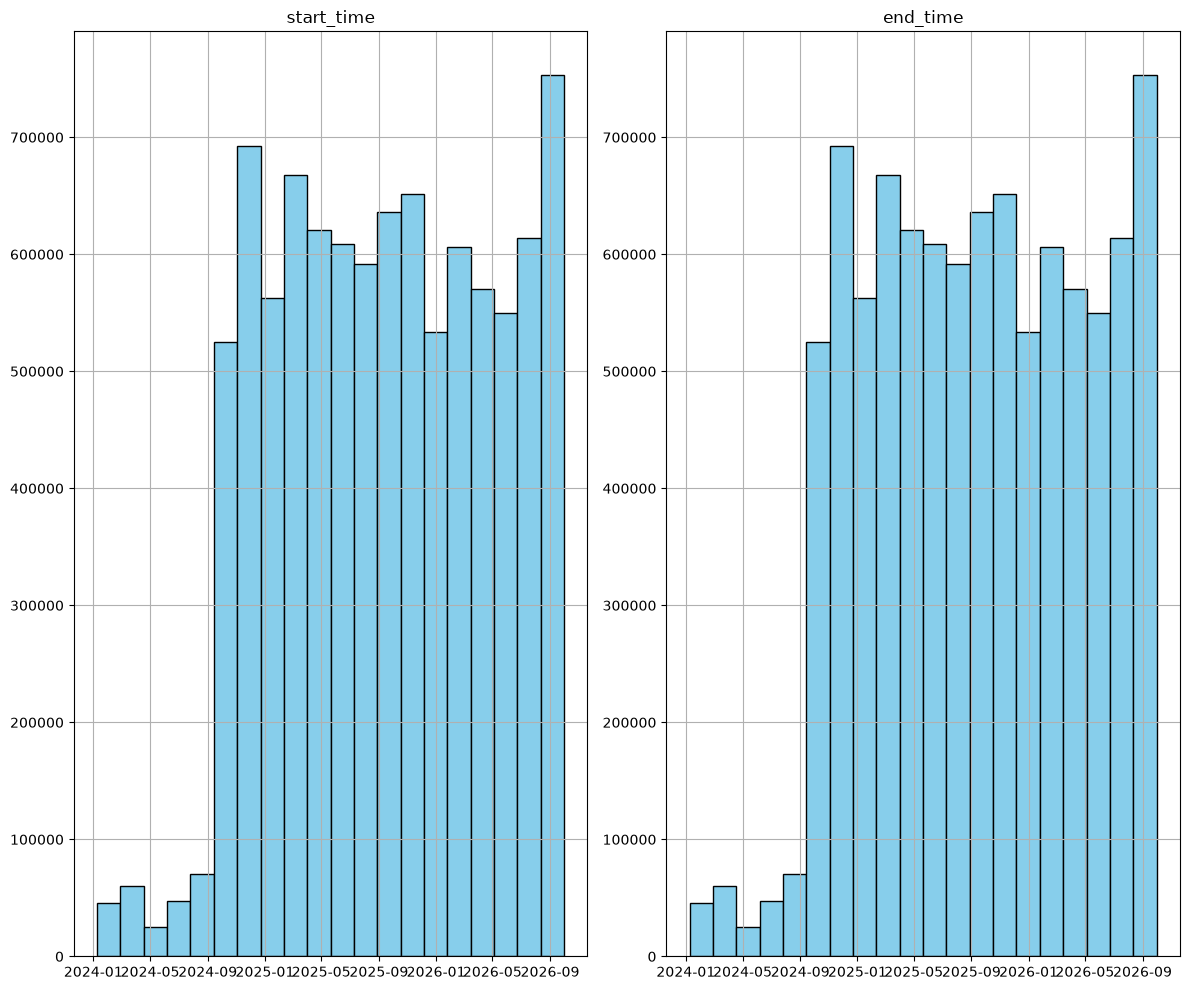

In [6]:
# Genera histogramas para todas las columnas numéricas del DataFrame
df_trips_all.hist(bins=20, figsize=(12, 10), color='skyblue', edgecolor='black')

plt.tight_layout()
plt.show()

Estos primeros histogramas no nos arrojan mucha información sobre comportamiento. Vamos a agregar unos campos nuevos al df_trips_all que nos permita realizar un mejor analisis. 

- Año: año de inicio
- Mes: Mes de inicio
- Dia: Dia de inicio
- Dia_semana: dia de la semana de inicio
- duracion_viaje: tiempo en minutos de duración del viaje. 

In [7]:
#Agregamos las variables nuevas


# Adicionamos campos de tiempo
df_trips_all["Año"] = df_trips_all["start_time"].dt.year
df_trips_all["Mes"] = df_trips_all["start_time"].dt.month
df_trips_all["Dia"] = df_trips_all["start_time"].dt.day
df_trips_all["Dia_semana"] = df_trips_all["start_time"].dt.weekday

# Calcular la duración del viaje en minutos
df_trips_all["duracion_viaje"] = (
    df_trips_all["end_time"] - df_trips_all["start_time"]
).dt.total_seconds() / 60.0

df_trips_all.head()

,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje
0,35406564,2024-01-09 00:00:00,2024-01-09 00:07:00,154,161,2024,1,9,1,7.0
1,35406567,2024-01-09 00:02:00,2024-01-09 00:08:00,50,156,2024,1,9,1,6.0
2,35406571,2024-01-09 00:02:00,2024-01-09 00:18:00,64,273,2024,1,9,1,16.0
3,35406572,2024-01-09 00:03:00,2024-01-09 00:10:00,271,164,2024,1,9,1,7.0
4,35406573,2024-01-09 00:03:00,2024-01-09 00:19:00,199,63,2024,1,9,1,16.0


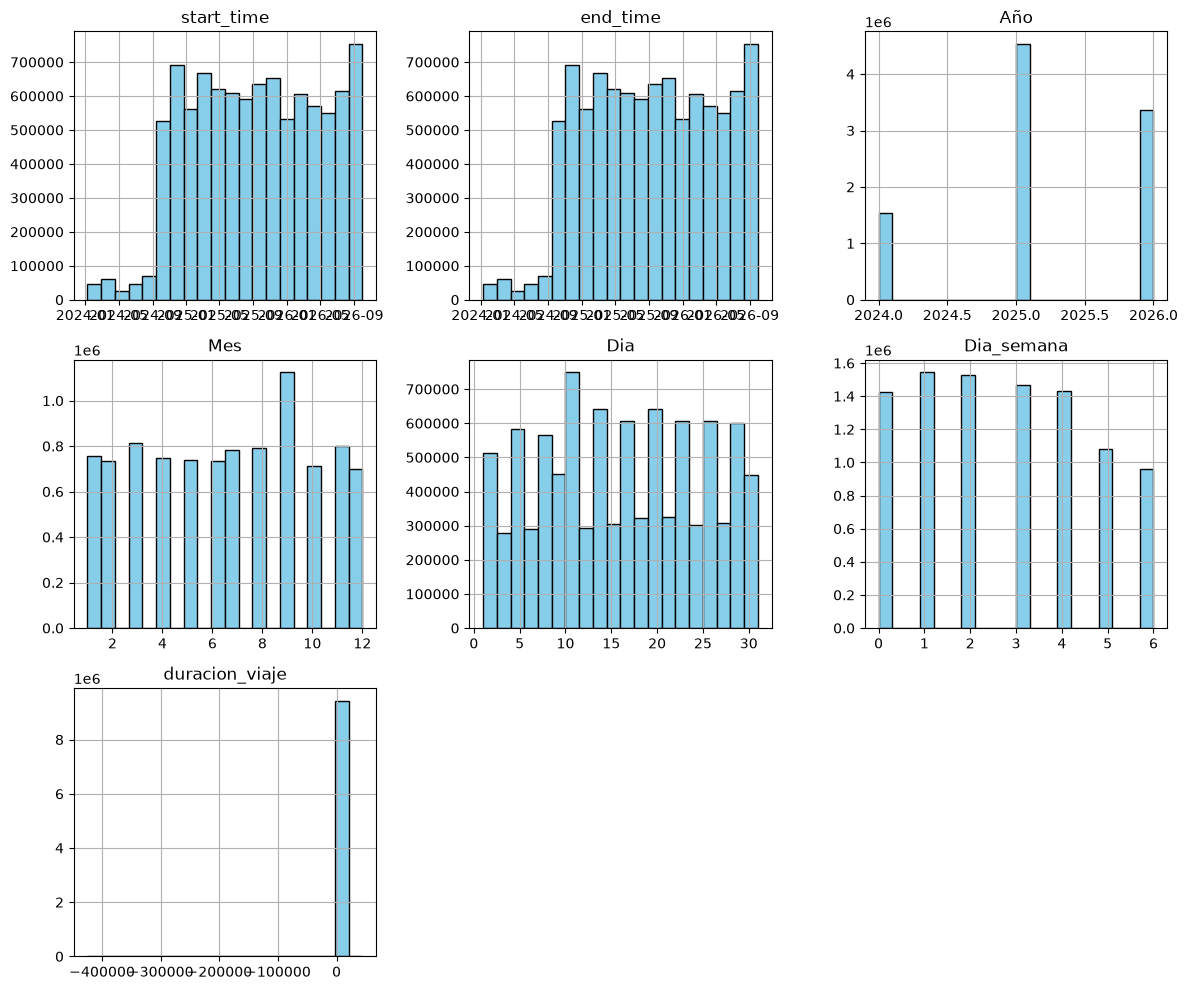

In [8]:
# Genera histogramas para todas las columnas numéricas del DataFrame
df_trips_all.hist(bins=20, figsize=(12, 10), color='skyblue', edgecolor='black')

plt.tight_layout()
plt.show()

De este análisis podemos ver que hay algunos comportamientos a señalar: 
- Los días con más uso son entre el 1 y 3, de Martes  a Jueves. El fin de semana el uso baja drásticamente. 
- Vemos esa misma estancionalidad en la gráfica por día del mes, hay un bajón cada fin de semana, pero también hay una tendencia a que en la mitad del mes es una epoca de uso alto. 
- En cuanto a los meses, si hay una reducción de uso a partir del mes 8, pudiendose ver afectado por el otoño-invierno. 
- En el 2025 hubo una reducción en el uso con respecto a 2024. Sin embargo, dos periodos es una ventana de tiempo muy corta para determinar una tendencia en reducción de uso. 

Sobre el tiempo de duración, se realizará un boxplot para analizar si hay datos atipicos

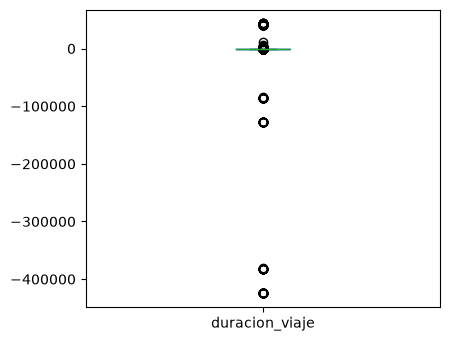

In [9]:
df_trips_all["duracion_viaje"].plot(
    kind='box', 
    subplots=True, 
    layout=(3, 3), 
    figsize=(12, 10), 
    sharex=False, 
    sharey=False
)

plt.tight_layout()
plt.show()

In [10]:
# Filtrar los viajes con una duración menor a 0 minutos
df_negativos = df_trips_all[df_trips_all['duracion_viaje'] < 0]

# Ver cuántos registros cumplen con esta condición y mostrar los primeros
print(f'Total de viajes menores a 0 minutos: {len(df_negativos):,}')

print('Primeros registros de viajes con duración negativa:')
display(df_negativos.head())

Total de viajes menores a 0 minutos: 115
Primeros registros de viajes con duración negativa:


,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje
164127,35593231,2024-12-09 23:39:00,2024-09-13 00:00:00,55,257,2024,12,9,0,-126699.0
164129,35593233,2024-12-09 23:39:00,2024-09-13 00:00:00,55,257,2024,12,9,0,-126699.0
164131,35593235,2024-12-09 23:39:00,2024-09-13 00:02:00,55,257,2024,12,9,0,-126697.0
164132,35593236,2024-12-09 23:40:00,2024-09-13 00:04:00,289,12,2024,12,9,0,-126696.0
164137,35593243,2024-12-09 23:41:00,2024-09-13 00:03:00,58,33,2024,12,9,0,-126698.0


Vemos que hay unos datos que tienen un tiempo de inicio mayor al final, lo que indica que por calculo el viaje tendria una duracion negativa. 

Son 115 registros de 9177953, representando el 0.0012%. Se propone eliminar estos registros, pudiendo tener errores de registro en otros campos. 

In [11]:
df_trips_limpio = df_trips_all[df_trips_all['start_time'] <= df_trips_all['end_time']].copy()

print(f'Total de viajes antes de limpiar los registros con duración negativa: {len(df_trips_all):,}')
print(f'Total de viajes después de limpiar los registros con duración negativa: {len(df_trips_limpio):,}')

Total de viajes antes de limpiar los registros con duración negativa: 9,433,997
Total de viajes después de limpiar los registros con duración negativa: 9,433,882


Revisión de duplicados

In [12]:
# Verificar si hay registros duplicados y si fuera así, elimínalos del dataframe.

duplicate_rows = df_trips_limpio[df_trips_limpio.duplicated()].index #Guardo en un array los index de los registros duplicados
longitud_antes = df_trips_limpio.shape[0]
print('Antes de eliminar duplicados:',longitud_antes)
print('Tenemos:',len(duplicate_rows),'registros duplicados')
df_trips_limpio = df_trips_limpio.drop(index= duplicate_rows) #Elimino los renglones que se repiten
longitud_despues = df_trips_limpio.shape[0]
print('Después de eliminar duplicados:',longitud_despues)

#Reinicio el index por si eliminó columnas

df_trips_limpio = df_trips_limpio.reset_index(drop=True) #Reinicio el index

Antes de eliminar duplicados: 9433882
Tenemos: 758 registros duplicados
Después de eliminar duplicados: 9433124


# Propuesta de dataframe final

Considerando la información contenida en el data frame "df_trips_limpio" y la información del catálogo de df_stations se realiza la propuesta de generar un data frame final enriquecido con la información geográfica y de capacidades de las estaciones de origen y destino

In [13]:
df_stations.head()

,station_id,station_name,latitude,longitude,capacity
0,2,(GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.,20.666378,-103.348820,15
1,3,(GDL-002) C. Colonias / Av. Niños héroes,20.667228,-103.366000,15
2,4,(GDL-003) C. Vidrio / Av. Chapultepec,20.667690,-103.368252,19
3,5,(GDL-004) C. Ghilardi /C. Miraflores,20.691847,-103.362549,19
4,6,(GDL-005) C. San Diego /Calzada Independencia,20.681158,-103.339363,11


In [14]:
df_trips_limpio.head()

,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje
0,35406564,2024-01-09 00:00:00,2024-01-09 00:07:00,154,161,2024,1,9,1,7.0
1,35406567,2024-01-09 00:02:00,2024-01-09 00:08:00,50,156,2024,1,9,1,6.0
2,35406571,2024-01-09 00:02:00,2024-01-09 00:18:00,64,273,2024,1,9,1,16.0
3,35406572,2024-01-09 00:03:00,2024-01-09 00:10:00,271,164,2024,1,9,1,7.0
4,35406573,2024-01-09 00:03:00,2024-01-09 00:19:00,199,63,2024,1,9,1,16.0


In [15]:
# Realizar los merges para enriquecer el dataset de viajes con la información de las estaciones de origen y destino

# Merge para obtener los datos de la estación de ORIGEN
df_merged = df_trips_all.merge(
    df_stations[['station_id', 'latitude', 'longitude', 'capacity']],  # <-- Incluimos 'station_id aquí'
    left_on='origin_station_id',
    right_on='station_id',
    how='left'
).rename(columns={
    'latitude': 'origin_latitude',
    'longitude': 'origin_longitude',
    'capacity': 'origin_capacity'
}).drop(columns=['station_id']) # Limpiamos la columna auxiliar del id de estación

# Merge para obtener los datos de la estación de DESTINO
df_merged = df_merged.merge(
    df_stations[['station_id', 'latitude', 'longitude', 'capacity']],  # <-- Incluimos 'station_id' aquí también
    left_on='destination_station_id',
    right_on='station_id',
    how='left'
).rename(columns={
    'latitude': 'destination_latitude',
    'longitude': 'destination_longitude',
    'capacity': 'destination_capacity'
}).drop(columns=['station_id']) # Limpiamos de nuevo la columna auxiliar

# Resultado: Un dataset enriquecido con la información espacial y estructural completa
print(f"Dimensiones del dataset final enriquecido: {df_merged.shape}")
df_merged.head()

Dimensiones del dataset final enriquecido: (9433997, 16)


,trip_id,start_time,end_time,origin_station_id,destination_station_id,Año,Mes,Dia,Dia_semana,duracion_viaje,origin_latitude,origin_longitude,origin_capacity,destination_latitude,destination_longitude,destination_capacity
0,35406564,2024-01-09 00:00:00,2024-01-09 00:07:00,154,161,2024,1,9,1,7.0,20.694930,-103.373330,15.0,20.693240,-103.367570,15.0
1,35406567,2024-01-09 00:02:00,2024-01-09 00:08:00,50,156,2024,1,9,1,6.0,20.674721,-103.358548,23.0,20.684560,-103.356990,15.0
2,35406571,2024-01-09 00:02:00,2024-01-09 00:18:00,64,273,2024,1,9,1,16.0,20.673072,-103.365055,15.0,20.694060,-103.348240,23.0
3,35406572,2024-01-09 00:03:00,2024-01-09 00:10:00,271,164,2024,1,9,1,7.0,20.685040,-103.347960,31.0,20.688598,-103.358467,19.0
4,35406573,2024-01-09 00:03:00,2024-01-09 00:19:00,199,63,2024,1,9,1,16.0,20.672070,-103.379970,15.0,20.671778,-103.361274,19.0


# P3 - Clustering

### Preparar los datos para el clustering

In [16]:
# Copiar DataFrames
trips = df_trips_limpio.copy()
stations = df_stations.copy()

# Validar las columnas necesarias
required_trips = ["start_time", "origin_station_id", "destination_station_id"]
required_stations = ["station_id", "latitude", "longitude", "capacity"]

# Homologar identificadores
trips["origin_station_id"] = (trips["origin_station_id"].astype("string").str.strip())
trips["destination_station_id"] = (trips["destination_station_id"].astype("string").str.strip())
stations["station_id"] = (stations["station_id"].astype("string").str.strip())

# Convertir fecha de inicio sea datetime
trips["start_time"] = pd.to_datetime(trips["start_time"], errors="coerce")

# Eliminar viajes sin fecha o sin identificador de origen/destino
trips = trips.dropna(subset=["start_time", "origin_station_id", "destination_station_id"]).copy()

# Construir las variables temporales necesarias
trips["hora_inicio"] = trips["start_time"].dt.hour
trips["dia_semana"] = trips["start_time"].dt.dayofweek

# Convertir las coordenadas y la capacidad a valores numéricos
for col in ["latitude", "longitude", "capacity"]:
    stations[col] = pd.to_numeric(stations[col], errors="coerce")

# Eliminar identificadores vacíos y duplicados en el catálogo
stations = stations.dropna(subset=["station_id"])
stations = stations.drop_duplicates(subset=["station_id"], keep="first").copy()

print("Viajes disponibles:", f"{len(trips):,}")
print("Estaciones en el catálogo:", f"{len(stations):,}")

Viajes disponibles: 9,433,124
Estaciones en el catálogo: 484


### Construir las variables agregadas por estación

In [17]:
# Viajes iniciados por estación
salidas = (trips.groupby("origin_station_id").size().rename_axis("station_id").rename("viajes_iniciados"))

# Viajes finalizados por estación
llegadas = (trips.groupby("destination_station_id").size().rename_axis("station_id").rename("viajes_finalizados"))

# Unir indicadores de uso
uso = pd.concat([salidas, llegadas], axis=1).fillna(0)

uso["total_viajes"] = (uso["viajes_iniciados"] + uso["viajes_finalizados"])

# Perfil horario de salidas
perfil_horario = pd.crosstab(trips["origin_station_id"], trips["hora_inicio"])

perfil_horario = perfil_horario.reindex(columns=range(24), fill_value=0)

perfil_horario.columns = [f"salidas_hora_{h:02d}" for h in range(24)]
perfil_horario.index.name = "station_id"

# Perfil por día de la semana
perfil_dia = pd.crosstab(trips["origin_station_id"], trips["dia_semana"])

perfil_dia = perfil_dia.reindex(columns=range(7), fill_value=0)

perfil_dia.columns = [f"salidas_dia_{d}" for d in range(7)]
perfil_dia.index.name = "station_id"

# Integrar todos los indicadores de uso
features = (uso.join(perfil_horario, how="outer").join(perfil_dia, how="outer").fillna(0).reset_index())

# Incorporar ubicación y capacidad de las estaciones
features = features.merge(stations[["station_id", "latitude", "longitude", "capacity"]], on="station_id", how="left", validate="one_to_one")

# Conservar estaciones con coordenadas válidas para poder
features = features.dropna(subset=["latitude", "longitude"]).copy()

# Evitar valores negativos en los indicadores de uso
columnas_uso = [
    c for c in features.columns
    if c.startswith("viajes_")
    or c.startswith("total_viajes")
    or c.startswith("salidas_hora_")
    or c.startswith("salidas_dia_")
]

features[columnas_uso] = features[columnas_uso].clip(lower=0)

print("Dimensiones de la tabla de estaciones:", features.shape)
display(features.head())

Dimensiones de la tabla de estaciones: (470, 38)


,station_id,viajes_iniciados,viajes_finalizados,total_viajes,salidas_hora_00,salidas_hora_01,salidas_hora_02,salidas_hora_03,salidas_hora_04,salidas_hora_05,...,salidas_dia_0,salidas_dia_1,salidas_dia_2,salidas_dia_3,salidas_dia_4,salidas_dia_5,salidas_dia_6,latitude,longitude,capacity
0,10,29252,29623,58875,92,0,0,0,0,184,...,4481,4751,4933,4630,4472,3441,2544,20.681953,-103.349992,15.0
1,100,6672,5263,11935,15,0,0,0,0,165,...,1075,1117,1251,1051,1124,629,425,20.723889,-103.394585,11.0
2,101,3923,3110,7033,9,0,0,0,0,168,...,600,670,696,681,594,416,266,20.726558,-103.389242,11.0
3,102,28059,26939,54998,22,0,0,0,0,127,...,4395,4746,4792,4631,4436,2851,2208,20.728538,-103.390297,19.0
4,103,11084,9696,20780,43,0,0,0,0,6,...,1766,1986,2054,1928,1758,807,785,20.720438,-103.391894,15.0


### Definir el baseline y el modelo candidato

In [18]:
# Baseline: volumen de uso de cada estación
variables_baseline = ["viajes_iniciados", "viajes_finalizados", "total_viajes"]

# Volumen + perfiles horarios y semanales
variables_candidato = (variables_baseline
                        + [c for c in features.columns if c.startswith("salidas_hora_")]
                        + [c for c in features.columns if c.startswith("salidas_dia_")]
                    )

# Eliminar estaciones sin actividad en el periodo analizado
features = features.loc[features["total_viajes"] > 0].reset_index(drop=True)

# Escalado independiente de cada conjunto de variables
scaler_base = StandardScaler()
X_base = scaler_base.fit_transform(features[variables_baseline])

scaler_candidato = StandardScaler()
X_candidato = scaler_candidato.fit_transform(features[variables_candidato])

print("Número de estaciones analizadas:", len(features))
print("Variables baseline:", len(variables_baseline))
print("Variables candidato:", len(variables_candidato))

Número de estaciones analizadas: 470
Variables baseline: 3
Variables candidato: 34


### Entrenar los modelos y calcular las métricas

In [ ]:
def evaluar_kmeans(X, k=3, nombre="Modelo"):
    """Entrena K-Means y calcula métricas de clustering."""

    if len(X) <= k:
        raise ValueError("Se necesitan más estaciones que clusters.")

    modelo = KMeans(n_clusters=k, random_state=42, n_init=10)

    etiquetas = modelo.fit_predict(X)

    # Silhouette requiere al menos 2 grupos y menos grupos que observaciones
    n_clusters_obtenidos = len(np.unique(etiquetas))

    if 1 < n_clusters_obtenidos < len(X):
        silhouette = silhouette_score(X, etiquetas)
        davies_bouldin = davies_bouldin_score(X, etiquetas)
        calinski_harabasz = calinski_harabasz_score(X, etiquetas)
    else:
        silhouette = np.nan
        davies_bouldin = np.nan
        calinski_harabasz = np.nan

    metricas = {
        "Modelo": nombre,
        "k": k,
        "Silhouette": silhouette,
        "Davies-Bouldin": davies_bouldin,
        "Calinski-Harabasz": calinski_harabasz,
        "Inercia": modelo.inertia_
    }

    return modelo, etiquetas, metricas

# Entrenar ambos modelos con k=3
modelo_base, etiquetas_base, metricas_base = evaluar_kmeans(X_base, k=3, nombre="Baseline")
modelo_candidato, etiquetas_candidato, metricas_candidato = evaluar_kmeans(X_candidato, k=3, nombre="Candidato")

# Asignar etiquetas a las estaciones
features["cluster_baseline"] = etiquetas_base
features["cluster_candidato"] = etiquetas_candidato

# Comparación de métricas
comparacion = pd.DataFrame([metricas_base, metricas_candidato])

display(comparacion.round(4))

,Modelo,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Inercia
0,Baseline,3,0.6344,0.5119,894.2709,291.9485
1,Candidato,3,0.5505,0.7515,415.7445,5747.1878


### Seleccionar el número de grupos para el candidato

,Modelo,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Inercia
0,Candidato,2,0.5958,0.8375,394.9959,8665.9046
1,Candidato,3,0.5505,0.7515,415.7445,5747.1878
2,Candidato,4,0.4525,0.9723,386.7328,4579.1954
3,Candidato,5,0.4659,0.8991,350.3270,3981.4974
4,Candidato,6,0.3992,1.0743,319.4857,3596.8846
5,Candidato,7,0.3697,0.8656,311.1359,3175.6763
6,Candidato,8,0.3514,0.9883,295.0368,2921.2532
7,Candidato,9,0.3375,0.9325,292.3755,2630.9895
8,Candidato,10,0.3418,0.8573,289.9657,2394.6382


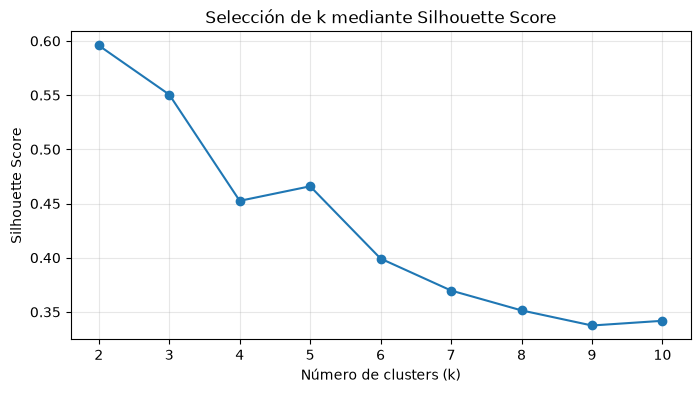

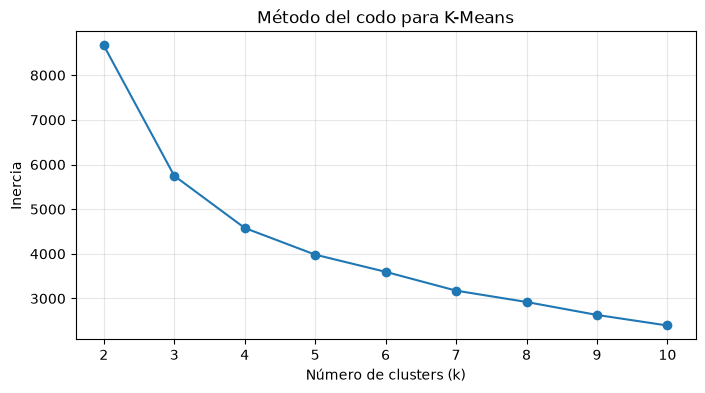

In [20]:
resultados_k = []

# Ajustar el rango según la cantidad de estaciones disponibles
max_k = min(10, len(features) - 1)

for k in range(2, max_k + 1):
    modelo, etiquetas, metricas = evaluar_kmeans(X_candidato, k=k, nombre="Candidato")
    resultados_k.append(metricas)

resultados_k = pd.DataFrame(resultados_k)
display(resultados_k.round(4))

# Gráfico de Silhouette Score
plt.figure(figsize=(8, 4))
plt.plot(resultados_k["k"], resultados_k["Silhouette"], marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Selección de k mediante Silhouette Score")
plt.xticks(resultados_k["k"])
plt.grid(True, alpha=0.3)
plt.show()

# Gráfico del método del codo
plt.figure(figsize=(8, 4))
plt.plot(resultados_k["k"], resultados_k["Inercia"], marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.title("Método del codo para K-Means")
plt.xticks(resultados_k["k"])
plt.grid(True, alpha=0.3)
plt.show()

### Visualizar los grupos de estaciones en la ciudad

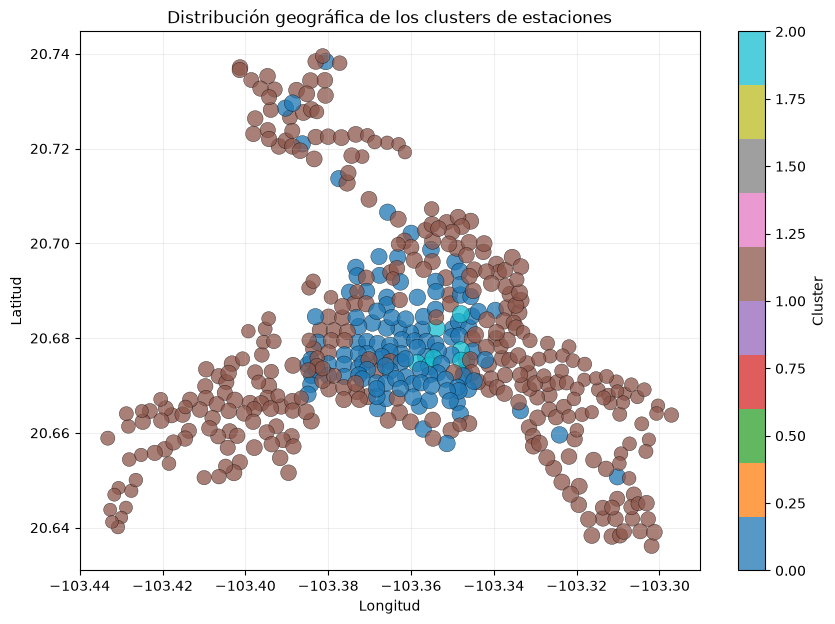

In [21]:
plt.figure(figsize=(10, 7))

scatter = plt.scatter(
    features["longitude"],
    features["latitude"],
    c=features["cluster_candidato"],
    cmap="tab10",
    s=30 + 10 * np.log1p(features["total_viajes"]),
    alpha=0.75,
    edgecolors="black",
    linewidths=0.3
)

plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.title("Distribución geográfica de los clusters de estaciones")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, alpha=0.2)
plt.show()

### Interpretar los grupos identificados

,numero_estaciones,promedio_salidas,promedio_llegadas,promedio_total_viajes,capacidad_promedio,latitud_media,longitud_media
cluster_candidato,,,,,,,
0,124,42760.66,42151.10,84911.76,17.38,20.68,-103.36
1,339,9317.50,9379.17,18696.67,16.78,20.68,-103.36
2,7,138601.43,146389.43,284990.86,25.29,20.68,-103.35


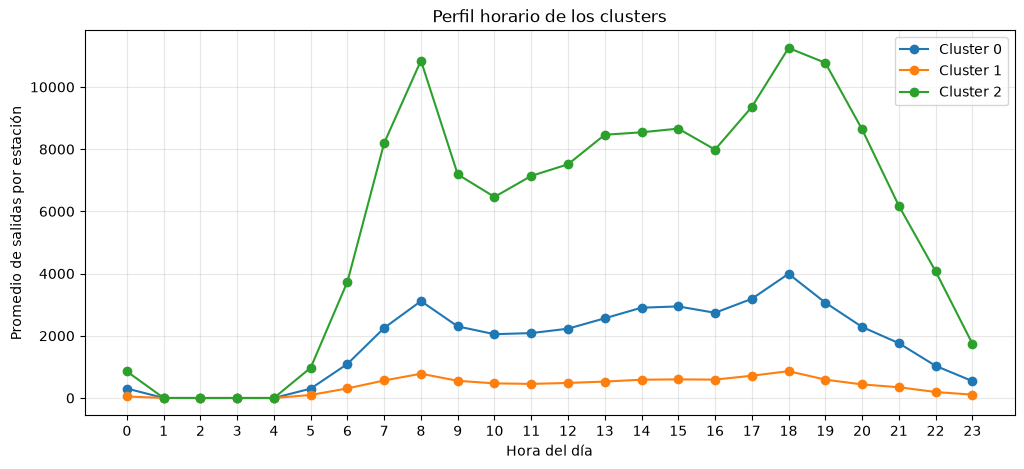

In [22]:
resumen_clusters = (
    features.groupby("cluster_candidato")
    .agg(
        numero_estaciones=("station_id", "nunique"),
        promedio_salidas=("viajes_iniciados", "mean"),
        promedio_llegadas=("viajes_finalizados", "mean"),
        promedio_total_viajes=("total_viajes", "mean"),
        capacidad_promedio=("capacity", "mean"),
        latitud_media=("latitude", "mean"),
        longitud_media=("longitude", "mean")
    )
    .round(2)
)

display(resumen_clusters)

# Identificar la hora de mayor actividad de cada cluster
columnas_horas = [c for c in features.columns if c.startswith("salidas_hora_")]

perfil_horario_clusters = (features.groupby("cluster_candidato")[columnas_horas].mean())

perfil_horario_clusters.columns = [c.replace("salidas_hora_", "") for c in columnas_horas]

plt.figure(figsize=(12, 5))

for cluster in perfil_horario_clusters.index:
    plt.plot(range(24), perfil_horario_clusters.loc[cluster].values, marker="o", label=f"Cluster {cluster}")

plt.xlabel("Hora del día")
plt.ylabel("Promedio de salidas por estación")
plt.title("Perfil horario de los clusters")
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### **Análisis de resultados**

Los resultados muestran que el baseline obtiene mejores métricas de agrupamiento que el modelo candidato para \(k=3\). Esto es importante porque demuestra que incorporar más variables no garantiza una segmentación de mayor calidad.


| Métrica | Baseline | Candidato | Mejor resultado |
| :--- | ---: | ---: | :--- |
| Silhouette Score | 0.6344 | 0.5505 | Baseline |
| Davies-Bouldin | 0.5119 | 0.7515 | Baseline |
| Calinski-Harabasz | 894.2709 | 415.7445 | Baseline |
| Inercia | 291.9485 | 5747.1878 | Baseline |
| Número de variables | 3 | 34 | — |

**Interpretación de las métricas:**
- **Silhouette Score:** El baseline alcanza 0.6344 frente a 0.5505 del candidato. Esto indica que las estaciones quedan, en general, mejor agrupadas y separadas utilizando las tres variables originales de volumen.
- **Davies-Bouldin:** El baseline obtiene 0.5119, inferior al 0.7515 del candidato. Esto sugiere que sus grupos son más compactos y diferenciados.
- **Calinski-Harabasz:** El baseline alcanza 894.2709, frente a 415.7445 del candidato. También favorece la estructura de agrupamiento del baseline.
- **Inercia:** Mide la dispersión intragrupo en el espacio de variables utilizado por cada modelo. Debido a que el candidato incluye 34 variables y el baseline solo tres, los valores no deben compararse directamente como si estuvieran en la misma escala.

En conjunto, las tres métricas de calidad favorecen al baseline. Una explicación posible es que los indicadores temporales adicionales incorporan variabilidad que dificulta la separación de los grupos. También podría influir la forma de escalar los perfiles horarios y semanales.


**Selección del número de clusters**

Los resultados del modelo candidato para distintos valores de $(k)$ permiten evaluar el equilibrio entre la separación de los grupos y su complejidad.

El mejor Silhouette Score se obtiene con $(k=2)$, mientras que el menor Davies-Bouldin y el mayor Calinski-Harabasz se obtienen con $(k=3)$. Por tanto, no existe un único valor de $(k)$ que gane en todas las métricas.
Para el análisis operativo, mantener tres clusters es una decisión defendible, porque permite estudiar tres perfiles de estaciones y obtiene los mejores resultados en dos de las tres métricas principales. Sin embargo, conviene comparar también $(k=2)$ y comprobar que los grupos sean útiles para la planeación urbana.


**Interpretación de los grupos identificados**

Los 470 registros de estaciones se distribuyen en tres clusters con perfiles de uso claramente diferentes según los promedios obtenidos.

| Cluster | Estaciones | Promedio de viajes totales | Capacidad promedio | Interpretación |
| :---: | ---: | ---: | ---: | :--- |
| 0 | 124 (26.4%) | 84,911.76 | 17.38 | Estaciones de uso elevado. |
| 1 | 339 (72.1%) | 18,696.67 | 16.78 | Estaciones de menor intensidad de uso. |
| 2 | 7 (1.5%) | 284,990.86 | 25.29 | Estaciones de uso excepcionalmente alto. |

* **Cluster 0: estaciones de uso elevado**
Agrupa 124 estaciones, con un promedio de aproximadamente 84,912 viajes entre iniciados y finalizados. Su capacidad media es de 17.38 unidades. Este grupo podría representar estaciones con una demanda considerable y servir para evaluar si la capacidad instalada guarda relación con el volumen de uso.

* **Cluster 1: estaciones de menor intensidad**
Es el grupo más numeroso, con 339 estaciones, equivalente al 72.1% del total. Registra un promedio de aproximadamente 18,697 viajes y una capacidad media de 16.78. Su tamaño sugiere que la mayoría de las estaciones analizadas tienen una intensidad de uso inferior a la de los otros grupos. No obstante, un menor volumen no significa necesariamente que una estación tenga un servicio deficiente: también puede responder a su ubicación, población cercana o función dentro del sistema.

* **Cluster 2: estaciones de uso excepcionalmente alto**
Está formado por siete estaciones, con un promedio cercano a 284,991 viajes y una capacidad media de 25.29. Su demanda media es aproximadamente 3.35 veces la del cluster 0 y 15.24 veces la del cluster 1. Estas estaciones merecen una evaluación específica, ya que podrían ser puntos estratégicos de conexión o concentración de viajes. También conviene revisar los datos para descartar que la diferencia se deba a anomalías o a periodos de observación distintos.

**Análisis de la distribución geográfica**

En el gráfico, las estaciones del grupo más numeroso se extienden por una superficie amplia, mientras que una parte importante de las estaciones de los otros grupos se concentra en la zona central. Esta distribución visual sugiere una posible concentración geográfica de estaciones con mayor intensidad de uso.
Sin embargo, el gráfico por sí solo no demuestra que la ubicación sea la causa de la demanda. Además, las coordenadas medias son muy similares entre los clusters debido a que la media geográfica puede ocultar diferencias locales. Para una interpretación espacial más sólida, convendría añadir un mapa base de la ciudad y examinar las siete estaciones del cluster 2 de forma individual.

In [23]:
from pathlib import Path

output_dir = Path("data")
output_dir.mkdir(exist_ok=True)

df_trips_limpio.to_csv(output_dir / "trips_clean.csv", index=False)
df_stations.to_csv(output_dir / "stations.csv", index=False)

print("Archivos exportados:")
print(output_dir / "trips_clean.csv")
print(output_dir / "stations.csv")

Archivos exportados:
data\trips_clean.csv
data\stations.csv
